# Comparing Scikit-Learn Classification Models

## 1. Cleaning the Data

In [67]:
# Import packages
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Create the df_top_1000 DataFrame
df_top_1000 = pl.read_csv("./data/top_1000_tags.csv", separator=",")
df_top_1000

,Unnamed: 0,Tag,Character,Narrative,Porn,Kink
i64,i64,str,str,str,str,str
0,0,"""5+1 Things""","""No Character""","""Format""","""Not Porn""","""Not Kink"""
1,1,"""69 (Sex Position)""","""No Character""","""Event-related/Action""","""Is Porn""","""Not Kink"""
2,2,"""Abandoned Work - Unfinished an…","""No Character""","""Format""","""Not Porn""","""Not Kink"""
3,3,"""Abuse""","""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""
4,4,"""Abusive Relationships""","""Relationship""","""Theme/Genre""","""Not Porn""","""Not Kink"""
…,…,…,…,…,…,…
995,995,"""Work In Progress""","""No Character""","""Format""","""Not Porn""","""Not Kink"""
996,996,"""Worldbuilding""","""No Character""","""WorldSetting""","""Not Porn""","""Not Kink"""
997,997,"""Yandere""","""Personality""","""No Narrative""","""Not Porn""","""Not Kink"""


In [3]:
# Add column names to a list
column_names = ['Character', 'Narrative', 'Porn', 'Kink']

In [4]:
# Count the amount of values for each unique value
for column in column_names:
    print(df_top_1000[column].value_counts())

shape: (6, 2)
┌──────────────────────┬───────┐
│ Character            ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ No Character         ┆ 475   │
│ Emotion/Mental State ┆ 152   │
│ Personality          ┆ 17    │
│ Biography            ┆ 106   │
│ Physical Feature     ┆ 55    │
│ Relationship         ┆ 195   │
└──────────────────────┴───────┘
shape: (7, 2)
┌──────────────────────┬───────┐
│ Narrative            ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ Format               ┆ 45    │
│ Theme/Genre          ┆ 163   │
│ Narrative Methods    ┆ 23    │
│ Event-related/Action ┆ 351   │
│ WorldSetting         ┆ 100   │
│ Plot                 ┆ 94    │
│ No Narrative         ┆ 224   │
└──────────────────────┴───────┘
shape: (2, 2)
┌──────────┬───────┐
│ Porn     ┆ count │
│ ---      ┆ ---   │
│ str      ┆ u32   │
╞══════════╪═══════╡
│ Is Porn  ┆ 143   │
│ Not P

## 2. Testing the Classification Models

In [5]:
# Assign X and y values
X = df_top_1000['Tag']
y_crc = df_top_1000[column_names[0]]
y_nrc = df_top_1000[column_names[1]]
y_ccp = df_top_1000[column_names[2]]
y_cck = df_top_1000[column_names[3]]

# Add y-values to a list
y_values = [y_crc, y_nrc, y_ccp, y_cck]

In [100]:
# Get the scores
scoring = {
    'accuracy': 'accuracy',
    'precision_macro': make_scorer(
        precision_score,
        average='macro',
        zero_division=0
    ),
    'precision_weighted': make_scorer(
        precision_score,
        average='weighted',
        zero_division=0
    ),
    'recall_macro': make_scorer(
        recall_score,
        average='macro',
        zero_division=0
    ),
    'recall_weighted': make_scorer(
        recall_score,
        average='weighted',
        zero_division=0
    ),
    'f1_macro': make_scorer(
        f1_score,
        average='macro',
        zero_division=0
    ),
    'f1_weighted': make_scorer(
        f1_score,
        average='weighted',
        zero_division=0
    )
}

In [ ]:
def compare_classifiers(y, classifier, classifier_name, classification):
    """
    Calculates the accuracy, precision, recall, and f1-scores, and classifies a given tag.

    Parameter:
        y (string): Contains the y-value.
        classifier (function): The classifier.
        classifier_name (string): Name of the classifier.
        classification (string): The overarching classification category.
    Returns:
        df_temp_stats (DataFrame): Contains the scores and prediction of the classifier.
    """
    # Calculate 5-fold cross validation
    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    kf_scores = cross_validate(
        Pipeline([
            ('tfidf', TfidfVectorizer()),
            ('clf', classifier)
        ]),
        X,
        y,
        cv=kf,
        scoring=scoring
    )

    # Generate out-of-fold predictions
    kf_pred = cross_val_predict(
        Pipeline([
            ('tfidf', TfidfVectorizer()),
            ('clf', classifier)
        ]),
        X,
        y,
        cv=kf
    )

    # Print the scores confusion matrix, and classification report for the classification
    print(f"{classification} | {classifier_name}:")

    labels = sorted(y.unique())

    # Plot a confusion matrix
    cm = confusion_matrix(y, kf_pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot()
    plt.xticks(rotation=90)
    plt.show()

    print(f"""Accuracy Mean": {kf_scores['test_accuracy'].mean()}
"Accuracy SD": {kf_scores['test_accuracy'].std()}
"F1 Macro Mean": {kf_scores['test_f1_macro'].mean()}
"F1 Macro SD": {kf_scores['test_f1_macro'].std()}
"F1 Weighted Mean": {kf_scores['test_f1_weighted'].mean()}
"F1 Weighted SD": {kf_scores['test_f1_weighted'].std()}
Classification Report:
{classification_report(y, kf_pred, labels=labels, zero_division=0)}""")

    df_temp_stats = pl.DataFrame({
        "Classifier": classifier_name,
        "Classification": classification,
        "Accuracy Mean": kf_scores['test_accuracy'].mean(),
        "Accuracy SD": kf_scores['test_accuracy'].std(),
        "Precision Macro Mean": kf_scores['test_precision_macro'].mean(),
        "Precision Macro SD": kf_scores['test_precision_macro'].std(),
        "Precision Weighted Mean": kf_scores['test_precision_weighted'].mean(),
        "Precision Weighted SD": kf_scores['test_precision_weighted'].std(),
        "Recall Macro Mean": kf_scores['test_recall_macro'].mean(),
        "Recall Macro SD": kf_scores['test_recall_macro'].std(),
        "Recall Weighted Mean": kf_scores['test_recall_weighted'].mean(),
        "Recall Weighted SD": kf_scores['test_recall_weighted'].std(),
        "F1 Macro Mean": kf_scores['test_f1_macro'].mean(),
        "F1 Macro SD": kf_scores['test_f1_macro'].std(),
        "F1 Weighted Mean": kf_scores['test_f1_weighted'].mean(),
        "F1 Weighted SD": kf_scores['test_f1_weighted'].std()
    })

    return df_temp_stats

Character-Related Category | Multinomial Naive Bayes:


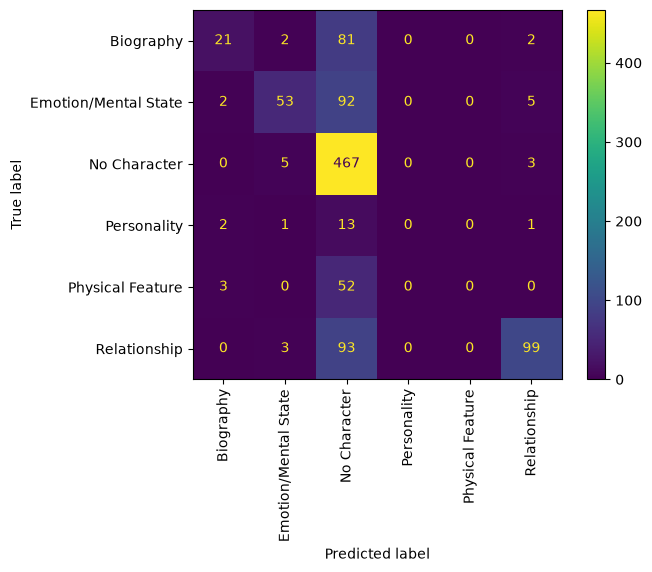

Accuracy Mean": 0.64
"Accuracy SD": 0.01923538406167136
"F1 Macro Mean": 0.36335819172823036
"F1 Macro SD": 0.028008985044936336
"F1 Weighted Mean": 0.5818490114076676
"F1 Weighted SD": 0.02545690894074876
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.75      0.20      0.31       106
Emotion/Mental State       0.83      0.35      0.49       152
        No Character       0.59      0.98      0.73       475
         Personality       0.00      0.00      0.00        17
    Physical Feature       0.00      0.00      0.00        55
        Relationship       0.90      0.51      0.65       195

            accuracy                           0.64      1000
           macro avg       0.51      0.34      0.36      1000
        weighted avg       0.66      0.64      0.58      1000

Character-Related Category | Complement Naive Bayes:


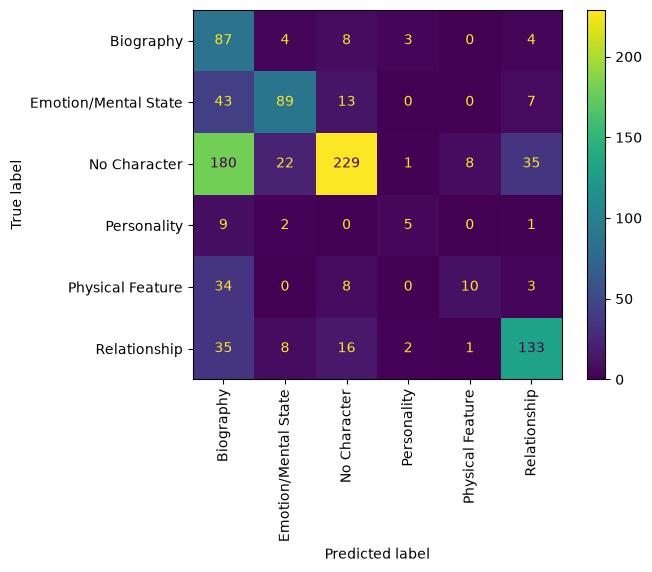

Accuracy Mean": 0.553
"Accuracy SD": 0.010770329614268982
"F1 Macro Mean": 0.4896492844134115
"F1 Macro SD": 0.05640959650830724
"F1 Weighted Mean": 0.5829192888359829
"F1 Weighted SD": 0.013959113861494206
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.22      0.82      0.35       106
Emotion/Mental State       0.71      0.59      0.64       152
        No Character       0.84      0.48      0.61       475
         Personality       0.45      0.29      0.36        17
    Physical Feature       0.53      0.18      0.27        55
        Relationship       0.73      0.68      0.70       195

            accuracy                           0.55      1000
           macro avg       0.58      0.51      0.49      1000
        weighted avg       0.71      0.55      0.58      1000

Character-Related Category | Linear Support Vector Classification:


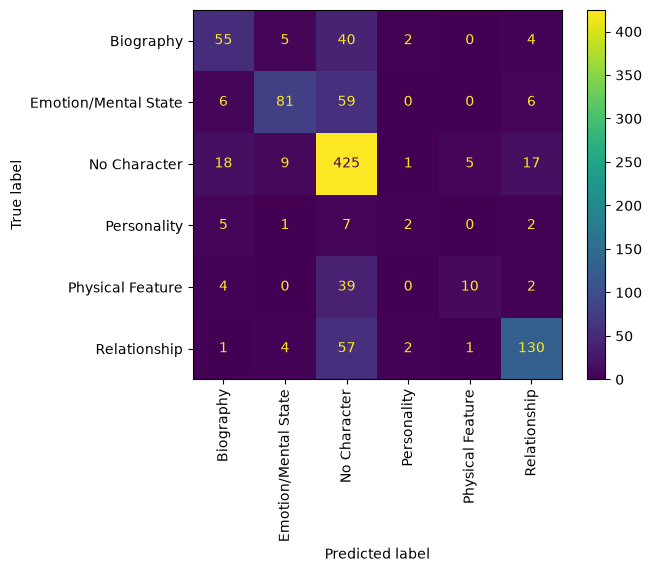

Accuracy Mean": 0.703
"Accuracy SD": 0.00509901951359279
"F1 Macro Mean": 0.5221474020140342
"F1 Macro SD": 0.022950460619578273
"F1 Weighted Mean": 0.6838657619350805
"F1 Weighted SD": 0.0068526304190039255
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.62      0.52      0.56       106
Emotion/Mental State       0.81      0.53      0.64       152
        No Character       0.68      0.89      0.77       475
         Personality       0.29      0.12      0.17        17
    Physical Feature       0.62      0.18      0.28        55
        Relationship       0.81      0.67      0.73       195

            accuracy                           0.70      1000
           macro avg       0.64      0.49      0.53      1000
        weighted avg       0.71      0.70      0.68      1000

Character-Related Category | Logistic Regression:


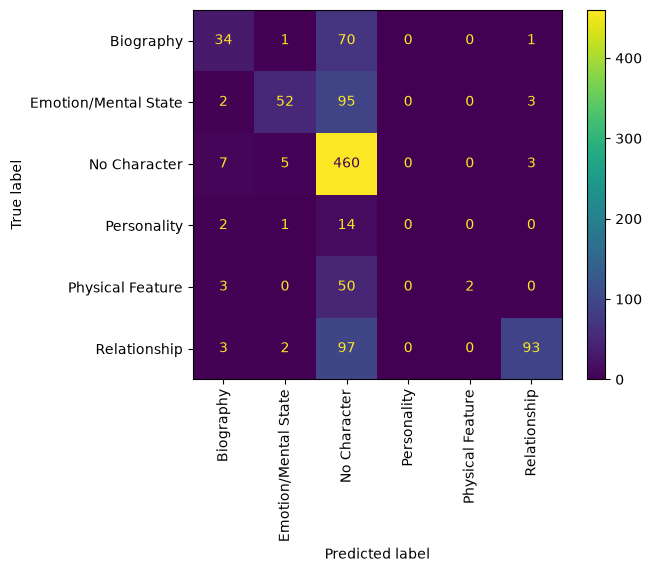

Accuracy Mean": 0.641
"Accuracy SD": 0.016552945357246864
"F1 Macro Mean": 0.390566410472177
"F1 Macro SD": 0.02331933179800642
"F1 Weighted Mean": 0.5923796590172705
"F1 Weighted SD": 0.020320233260760587
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.67      0.32      0.43       106
Emotion/Mental State       0.85      0.34      0.49       152
        No Character       0.59      0.97      0.73       475
         Personality       0.00      0.00      0.00        17
    Physical Feature       1.00      0.04      0.07        55
        Relationship       0.93      0.48      0.63       195

            accuracy                           0.64      1000
           macro avg       0.67      0.36      0.39      1000
        weighted avg       0.71      0.64      0.59      1000

Character-Related Category | K-Nearest Neighbors:


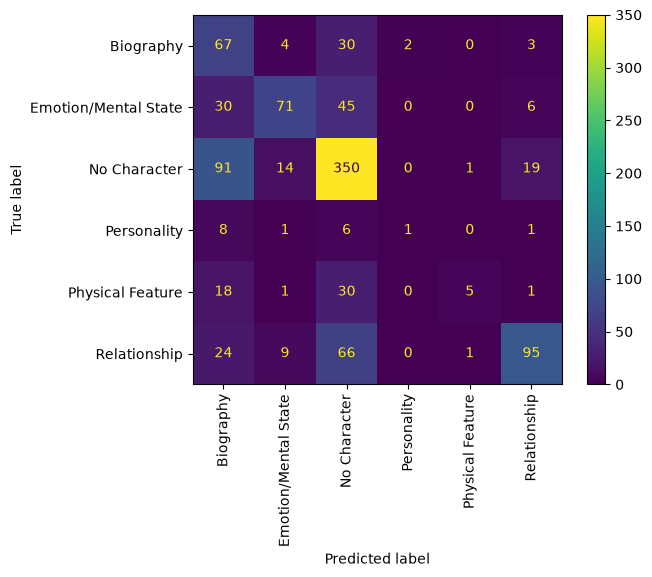

Accuracy Mean": 0.589
"Accuracy SD": 0.08315046602394963
"F1 Macro Mean": 0.42078030877042194
"F1 Macro SD": 0.0528761962213083
"F1 Weighted Mean": 0.5836939016488769
"F1 Weighted SD": 0.05761435931884411
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.28      0.63      0.39       106
Emotion/Mental State       0.71      0.47      0.56       152
        No Character       0.66      0.74      0.70       475
         Personality       0.33      0.06      0.10        17
    Physical Feature       0.71      0.09      0.16        55
        Relationship       0.76      0.49      0.59       195

            accuracy                           0.59      1000
           macro avg       0.58      0.41      0.42      1000
        weighted avg       0.65      0.59      0.59      1000

Character-Related Category | Support Vector Machines:


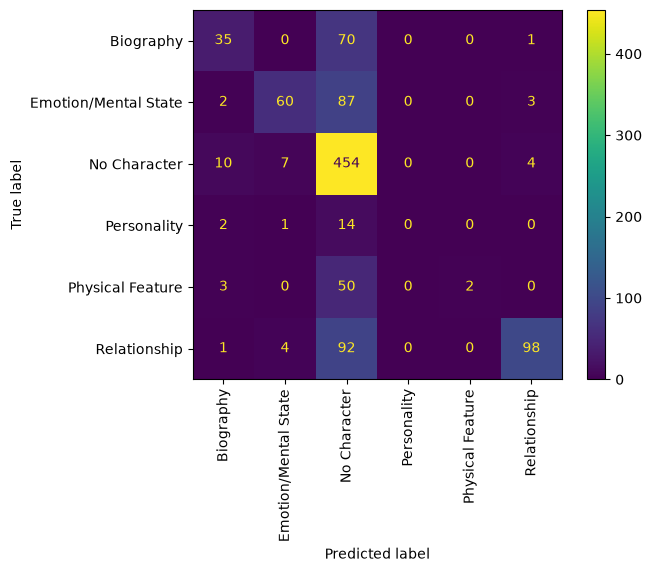

Accuracy Mean": 0.649
"Accuracy SD": 0.01743559577416271
"F1 Macro Mean": 0.40346116895164474
"F1 Macro SD": 0.020438498672330982
"F1 Weighted Mean": 0.6050410765000179
"F1 Weighted SD": 0.018560522326975692
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.66      0.33      0.44       106
Emotion/Mental State       0.83      0.39      0.54       152
        No Character       0.59      0.96      0.73       475
         Personality       0.00      0.00      0.00        17
    Physical Feature       1.00      0.04      0.07        55
        Relationship       0.92      0.50      0.65       195

            accuracy                           0.65      1000
           macro avg       0.67      0.37      0.40      1000
        weighted avg       0.71      0.65      0.61      1000

Character-Related Category | Decision Trees:


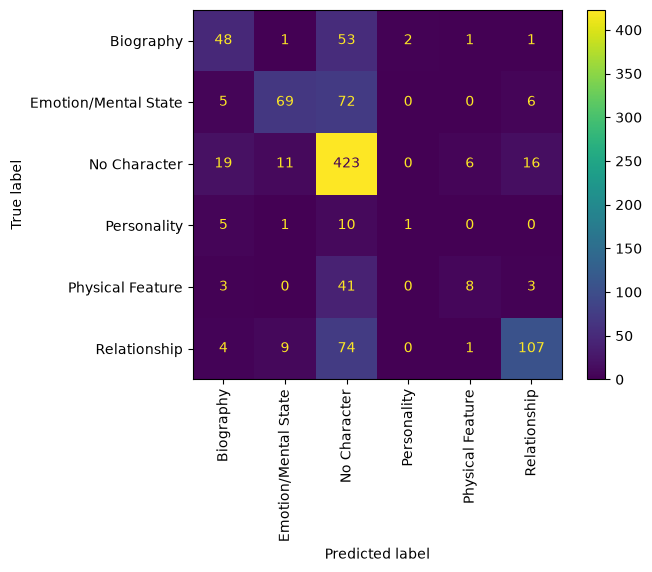

Accuracy Mean": 0.66
"Accuracy SD": 0.017029386365926415
"F1 Macro Mean": 0.47197212480230205
"F1 Macro SD": 0.01887846898383774
"F1 Weighted Mean": 0.6345923240933786
"F1 Weighted SD": 0.019946259530177188
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.57      0.45      0.51       106
Emotion/Mental State       0.76      0.45      0.57       152
        No Character       0.63      0.89      0.74       475
         Personality       0.33      0.06      0.10        17
    Physical Feature       0.50      0.15      0.23        55
        Relationship       0.80      0.55      0.65       195

            accuracy                           0.66      1000
           macro avg       0.60      0.43      0.46      1000
        weighted avg       0.66      0.66      0.63      1000

Character-Related Category | Random Forest:


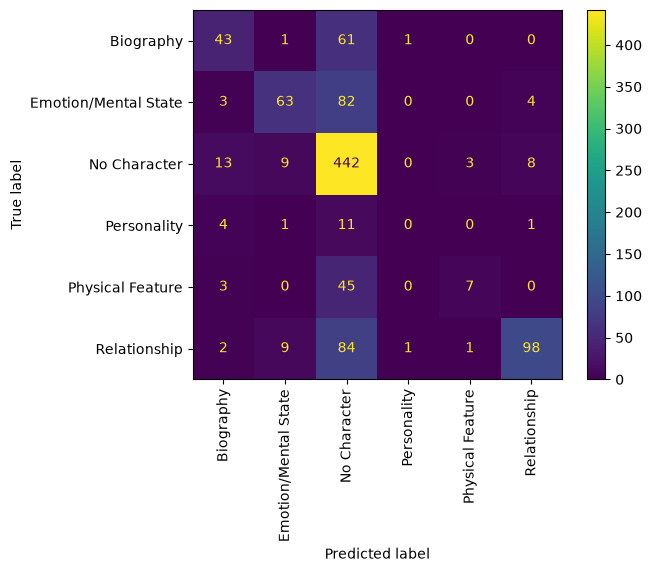

Accuracy Mean": 0.649
"Accuracy SD": 0.02059126028197402
"F1 Macro Mean": 0.42944499281889315
"F1 Macro SD": 0.030578554821768005
"F1 Weighted Mean": 0.6143212906706628
"F1 Weighted SD": 0.025107370341007716
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.63      0.41      0.49       106
Emotion/Mental State       0.76      0.41      0.54       152
        No Character       0.61      0.93      0.74       475
         Personality       0.00      0.00      0.00        17
    Physical Feature       0.64      0.13      0.21        55
        Relationship       0.88      0.50      0.64       195

            accuracy                           0.65      1000
           macro avg       0.59      0.40      0.44      1000
        weighted avg       0.68      0.65      0.62      1000

Character-Related Category | Gradient Boosting:


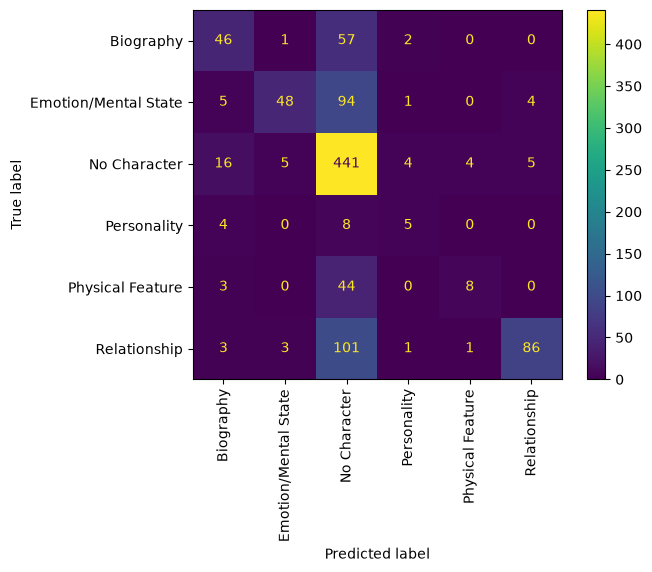

Accuracy Mean": 0.635
"Accuracy SD": 0.02569046515733028
"F1 Macro Mean": 0.4559442836849275
"F1 Macro SD": 0.06313567113588059
"F1 Weighted Mean": 0.6003776284138287
"F1 Weighted SD": 0.026089605274077318
Classification Report:
                      precision    recall  f1-score   support

           Biography       0.60      0.43      0.50       106
Emotion/Mental State       0.84      0.32      0.46       152
        No Character       0.59      0.93      0.72       475
         Personality       0.38      0.29      0.33        17
    Physical Feature       0.62      0.15      0.24        55
        Relationship       0.91      0.44      0.59       195

            accuracy                           0.63      1000
           macro avg       0.66      0.43      0.47      1000
        weighted avg       0.69      0.63      0.60      1000

Narrative-Related Category | Multinomial Naive Bayes:


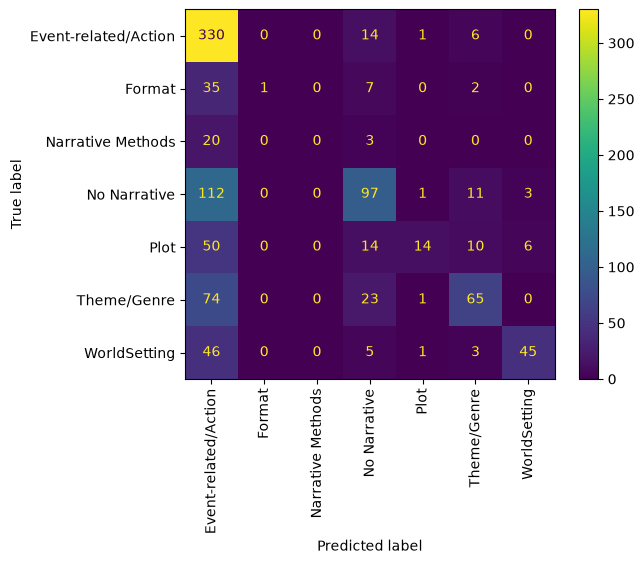

Accuracy Mean": 0.552
"Accuracy SD": 0.02249444375840396
"F1 Macro Mean": 0.3596015733404022
"F1 Macro SD": 0.013917451437646467
"F1 Weighted Mean": 0.5043002077536396
"F1 Weighted SD": 0.02094404439582718
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.49      0.94      0.65       351
              Format       1.00      0.02      0.04        45
   Narrative Methods       0.00      0.00      0.00        23
        No Narrative       0.60      0.43      0.50       224
                Plot       0.78      0.15      0.25        94
         Theme/Genre       0.67      0.40      0.50       163
        WorldSetting       0.83      0.45      0.58       100

            accuracy                           0.55      1000
           macro avg       0.62      0.34      0.36      1000
        weighted avg       0.62      0.55      0.51      1000

Narrative-Related Category | Complement Naive Bayes:


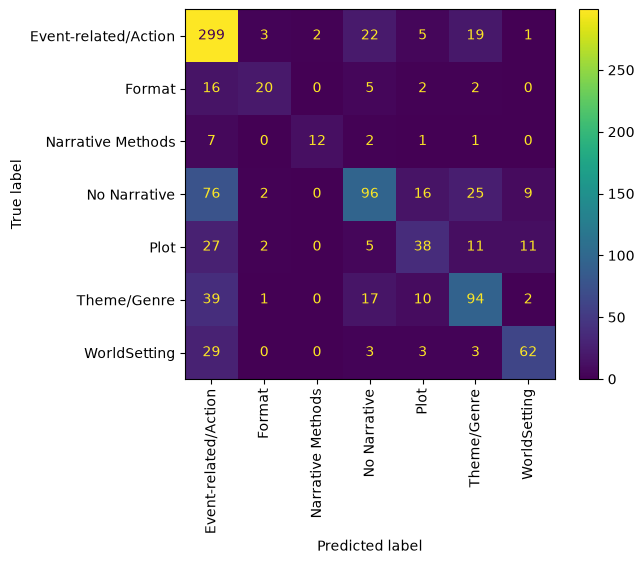

Accuracy Mean": 0.621
"Accuracy SD": 0.02200000000000002
"F1 Macro Mean": 0.5864455207230084
"F1 Macro SD": 0.04750969080070605
"F1 Weighted Mean": 0.6072633492374276
"F1 Weighted SD": 0.024726702106541983
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.61      0.85      0.71       351
              Format       0.71      0.44      0.55        45
   Narrative Methods       0.86      0.52      0.65        23
        No Narrative       0.64      0.43      0.51       224
                Plot       0.51      0.40      0.45        94
         Theme/Genre       0.61      0.58      0.59       163
        WorldSetting       0.73      0.62      0.67       100

            accuracy                           0.62      1000
           macro avg       0.67      0.55      0.59      1000
        weighted avg       0.63      0.62      0.61      1000

Narrative-Related Category | Linear Support Vector Classification:


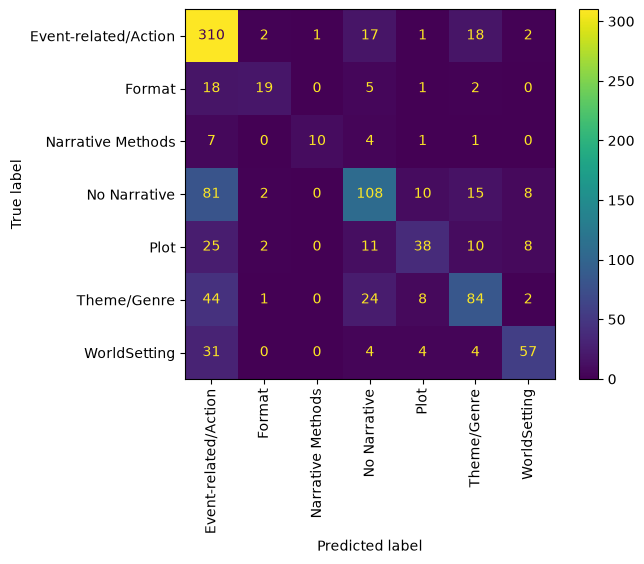

Accuracy Mean": 0.626
"Accuracy SD": 0.023108440016582705
"F1 Macro Mean": 0.5723391097565533
"F1 Macro SD": 0.05744977642801476
"F1 Weighted Mean": 0.6100563086626959
"F1 Weighted SD": 0.025348149982459836
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.60      0.88      0.72       351
              Format       0.73      0.42      0.54        45
   Narrative Methods       0.91      0.43      0.59        23
        No Narrative       0.62      0.48      0.54       224
                Plot       0.60      0.40      0.48        94
         Theme/Genre       0.63      0.52      0.57       163
        WorldSetting       0.74      0.57      0.64       100

            accuracy                           0.63      1000
           macro avg       0.69      0.53      0.58      1000
        weighted avg       0.64      0.63      0.61      1000

Narrative-Related Category | Logistic Regression:


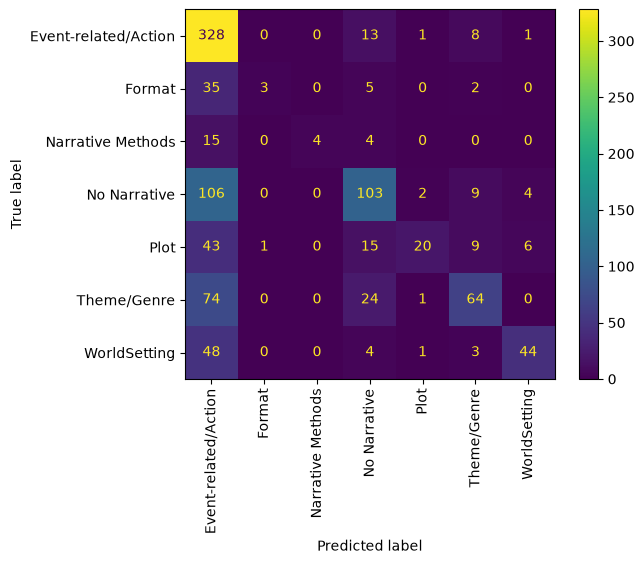

Accuracy Mean": 0.566
"Accuracy SD": 0.013190905958272886
"F1 Macro Mean": 0.42538763352963793
"F1 Macro SD": 0.017854705373344805
"F1 Weighted Mean": 0.5274394727203214
"F1 Weighted SD": 0.010780626172768681
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.51      0.93      0.66       351
              Format       0.75      0.07      0.12        45
   Narrative Methods       1.00      0.17      0.30        23
        No Narrative       0.61      0.46      0.53       224
                Plot       0.80      0.21      0.34        94
         Theme/Genre       0.67      0.39      0.50       163
        WorldSetting       0.80      0.44      0.57       100

            accuracy                           0.57      1000
           macro avg       0.73      0.38      0.43      1000
        weighted avg       0.64      0.57      0.53      1000

Narrative-Related Category | K-Nearest Neighbors:


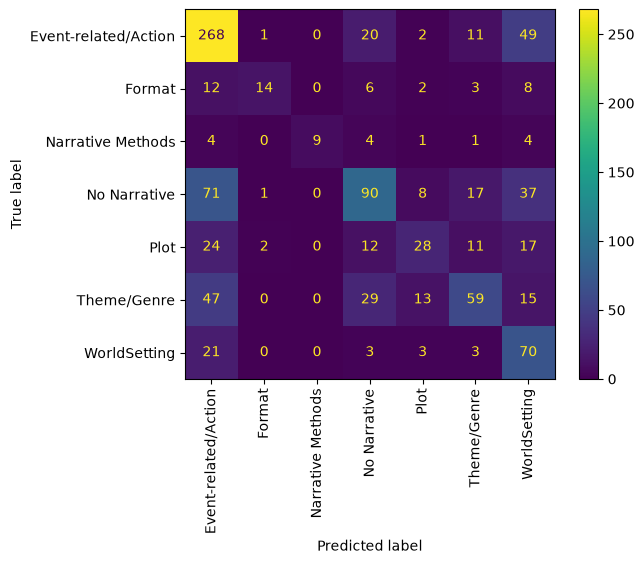

Accuracy Mean": 0.538
"Accuracy SD": 0.050059964043135306
"F1 Macro Mean": 0.4909234177100682
"F1 Macro SD": 0.034036336971316604
"F1 Weighted Mean": 0.5289282270251393
"F1 Weighted SD": 0.028513639274744436
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.60      0.76      0.67       351
              Format       0.78      0.31      0.44        45
   Narrative Methods       1.00      0.39      0.56        23
        No Narrative       0.55      0.40      0.46       224
                Plot       0.49      0.30      0.37        94
         Theme/Genre       0.56      0.36      0.44       163
        WorldSetting       0.35      0.70      0.47       100

            accuracy                           0.54      1000
           macro avg       0.62      0.46      0.49      1000
        weighted avg       0.56      0.54      0.53      1000

Narrative-Related Category | Support Vector Machines:


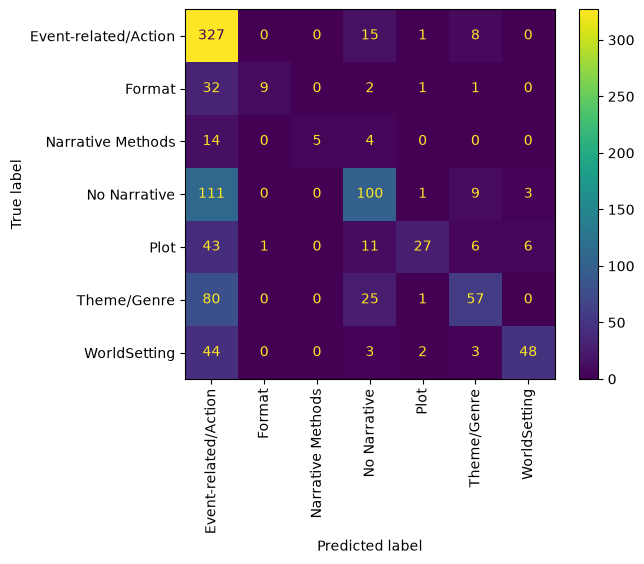

Accuracy Mean": 0.5730000000000001
"Accuracy SD": 0.00748331477354785
"F1 Macro Mean": 0.4751515883534565
"F1 Macro SD": 0.017298305051211233
"F1 Weighted Mean": 0.5424819983967148
"F1 Weighted SD": 0.00858337697809266
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.50      0.93      0.65       351
              Format       0.90      0.20      0.33        45
   Narrative Methods       1.00      0.22      0.36        23
        No Narrative       0.62      0.45      0.52       224
                Plot       0.82      0.29      0.43        94
         Theme/Genre       0.68      0.35      0.46       163
        WorldSetting       0.84      0.48      0.61       100

            accuracy                           0.57      1000
           macro avg       0.77      0.42      0.48      1000
        weighted avg       0.65      0.57      0.55      1000

Narrative-Related Category | Decision Trees:


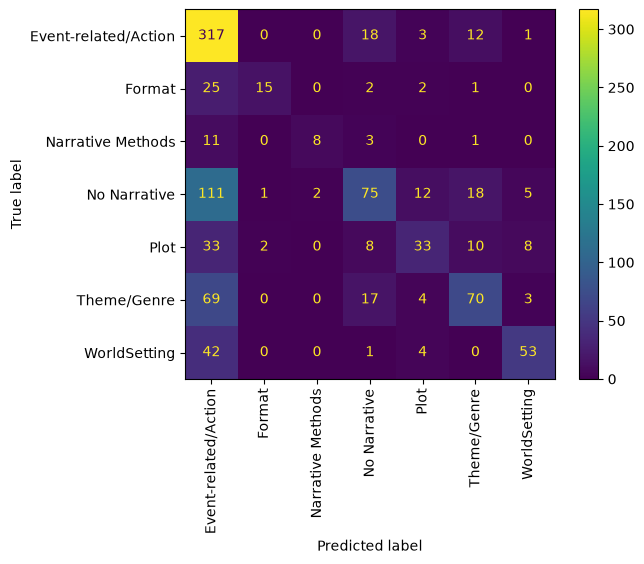

Accuracy Mean": 0.5609999999999999
"Accuracy SD": 0.017435595774162656
"F1 Macro Mean": 0.5053005022205271
"F1 Macro SD": 0.02940530278663954
"F1 Weighted Mean": 0.534803496438393
"F1 Weighted SD": 0.0228072115863047
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.52      0.90      0.66       351
              Format       0.83      0.33      0.48        45
   Narrative Methods       0.80      0.35      0.48        23
        No Narrative       0.60      0.33      0.43       224
                Plot       0.57      0.35      0.43        94
         Theme/Genre       0.62      0.43      0.51       163
        WorldSetting       0.76      0.53      0.62       100

            accuracy                           0.57      1000
           macro avg       0.67      0.46      0.52      1000
        weighted avg       0.61      0.57      0.55      1000

Narrative-Related Category | Random Forest:


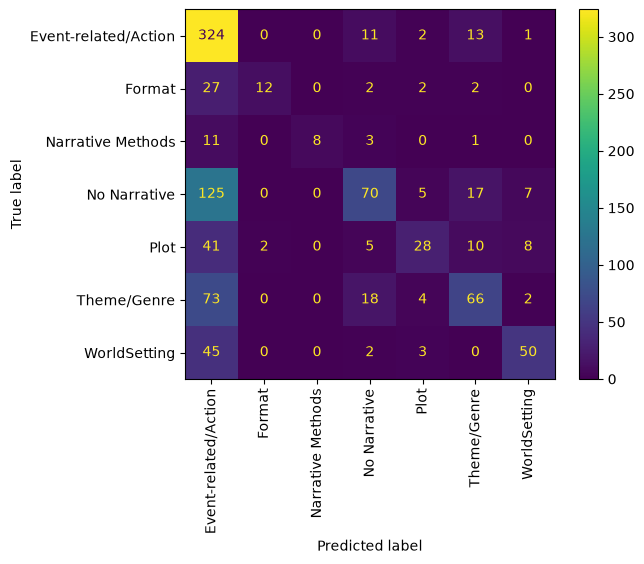

Accuracy Mean": 0.5549999999999999
"Accuracy SD": 0.013038404810405267
"F1 Macro Mean": 0.4862790268240462
"F1 Macro SD": 0.030801743085627113
"F1 Weighted Mean": 0.5242985548352108
"F1 Weighted SD": 0.013841224235561922
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.50      0.92      0.65       351
              Format       0.86      0.27      0.41        45
   Narrative Methods       1.00      0.35      0.52        23
        No Narrative       0.63      0.31      0.42       224
                Plot       0.64      0.30      0.41        94
         Theme/Genre       0.61      0.40      0.49       163
        WorldSetting       0.74      0.50      0.60       100

            accuracy                           0.56      1000
           macro avg       0.71      0.44      0.50      1000
        weighted avg       0.61      0.56      0.53      1000

Narrative-Related Category | Gradient Boosting:


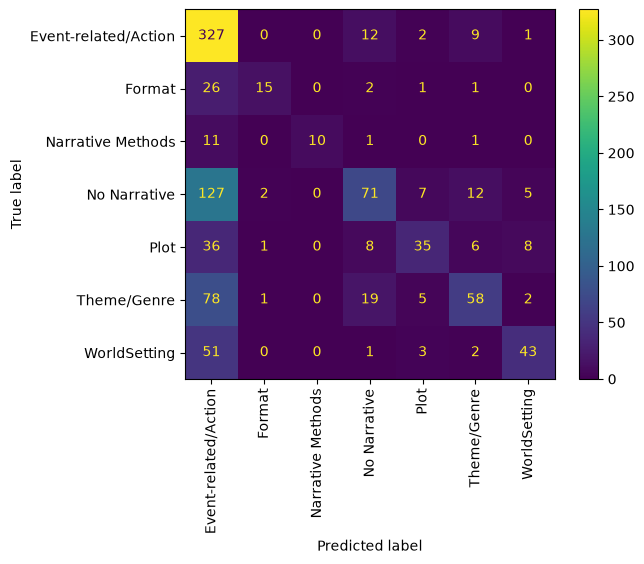

Accuracy Mean": 0.562
"Accuracy SD": 0.015684387141358086
"F1 Macro Mean": 0.51587451337278
"F1 Macro SD": 0.04078161611185498
"F1 Weighted Mean": 0.5319246475195912
"F1 Weighted SD": 0.01494646802177448
Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.50      0.93      0.65       351
              Format       0.79      0.33      0.47        45
   Narrative Methods       1.00      0.43      0.61        23
        No Narrative       0.62      0.32      0.42       224
                Plot       0.66      0.37      0.48        94
         Theme/Genre       0.65      0.36      0.46       163
        WorldSetting       0.73      0.43      0.54       100

            accuracy                           0.56      1000
           macro avg       0.71      0.45      0.52      1000
        weighted avg       0.61      0.56      0.53      1000

Content Control Porn | Multinomial Naive Bayes:


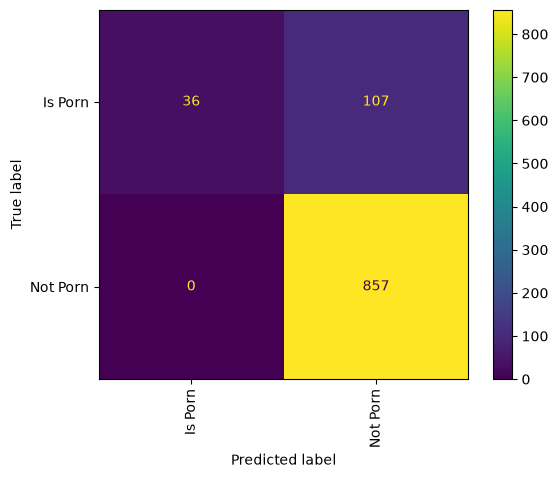

Accuracy Mean": 0.893
"Accuracy SD": 0.012083045973594582
"F1 Macro Mean": 0.6696313554028194
"F1 Macro SD": 0.04873961752798039
"F1 Weighted Mean": 0.8634256830225473
"F1 Weighted SD": 0.019429348874343885
Classification Report:
              precision    recall  f1-score   support

     Is Porn       1.00      0.25      0.40       143
    Not Porn       0.89      1.00      0.94       857

    accuracy                           0.89      1000
   macro avg       0.94      0.63      0.67      1000
weighted avg       0.90      0.89      0.86      1000

Content Control Porn | Complement Naive Bayes:


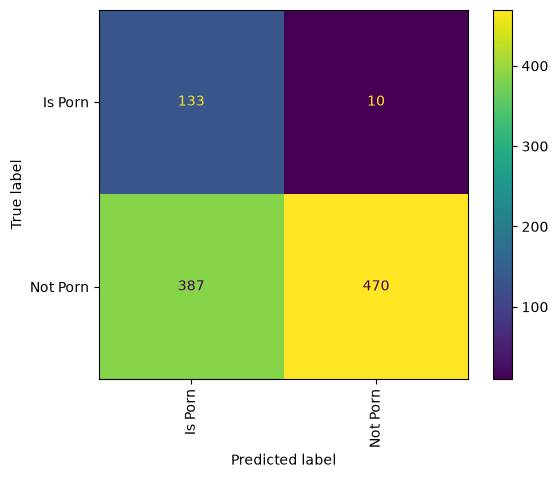

Accuracy Mean": 0.603
"Accuracy SD": 0.024819347291981732
"F1 Macro Mean": 0.5521241944636481
"F1 Macro SD": 0.019975424925200092
"F1 Weighted Mean": 0.6595929719285233
"F1 Weighted SD": 0.02271393786410581
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.26      0.93      0.40       143
    Not Porn       0.98      0.55      0.70       857

    accuracy                           0.60      1000
   macro avg       0.62      0.74      0.55      1000
weighted avg       0.88      0.60      0.66      1000

Content Control Porn | Linear Support Vector Classification:


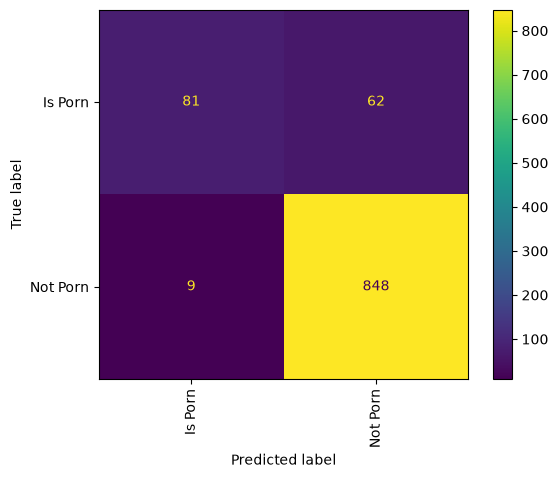

Accuracy Mean": 0.929
"Accuracy SD": 0.010677078252031298
"F1 Macro Mean": 0.8271727370150274
"F1 Macro SD": 0.028028441405875248
"F1 Weighted Mean": 0.9219262003892508
"F1 Weighted SD": 0.011914664897785051
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.90      0.57      0.70       143
    Not Porn       0.93      0.99      0.96       857

    accuracy                           0.93      1000
   macro avg       0.92      0.78      0.83      1000
weighted avg       0.93      0.93      0.92      1000

Content Control Porn | Logistic Regression:


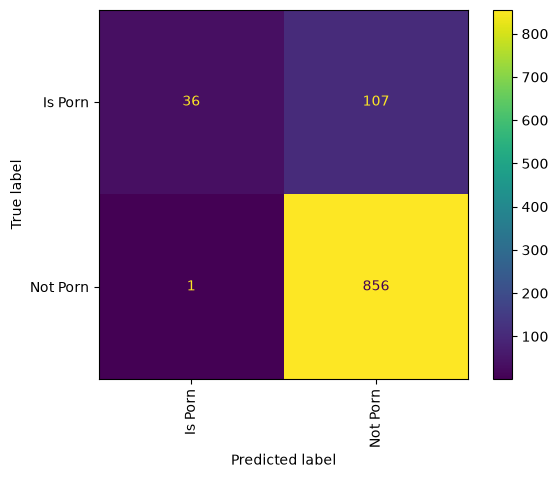

Accuracy Mean": 0.8920000000000001
"Accuracy SD": 0.013266499161421611
"F1 Macro Mean": 0.6677622810904658
"F1 Macro SD": 0.05364925699344821
"F1 Weighted Mean": 0.8625646827531703
"F1 Weighted SD": 0.02067344999483269
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.97      0.25      0.40       143
    Not Porn       0.89      1.00      0.94       857

    accuracy                           0.89      1000
   macro avg       0.93      0.63      0.67      1000
weighted avg       0.90      0.89      0.86      1000

Content Control Porn | K-Nearest Neighbors:


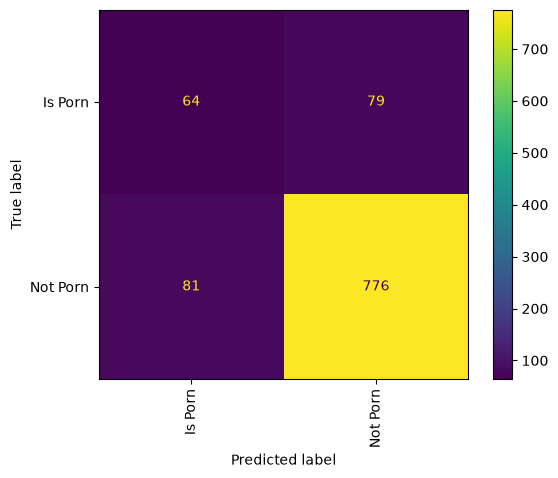

Accuracy Mean": 0.8400000000000001
"Accuracy SD": 0.13501851724856115
"F1 Macro Mean": 0.6953647742220831
"F1 Macro SD": 0.09503976091617448
"F1 Weighted Mean": 0.8383465040235297
"F1 Weighted SD": 0.10219516457147998
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.44      0.45      0.44       143
    Not Porn       0.91      0.91      0.91       857

    accuracy                           0.84      1000
   macro avg       0.67      0.68      0.68      1000
weighted avg       0.84      0.84      0.84      1000

Content Control Porn | Support Vector Machines:


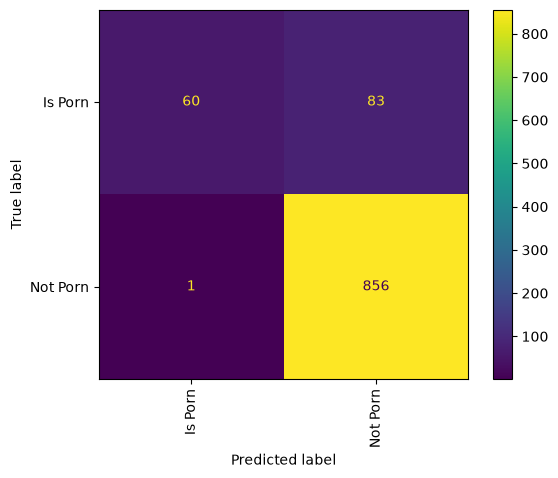

Accuracy Mean": 0.916
"Accuracy SD": 0.011575836902790236
"F1 Macro Mean": 0.7694663304620677
"F1 Macro SD": 0.03810111548766482
"F1 Weighted Mean": 0.9006439738879275
"F1 Weighted SD": 0.01560991915215386
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.98      0.42      0.59       143
    Not Porn       0.91      1.00      0.95       857

    accuracy                           0.92      1000
   macro avg       0.95      0.71      0.77      1000
weighted avg       0.92      0.92      0.90      1000

Content Control Porn | Decision Trees:


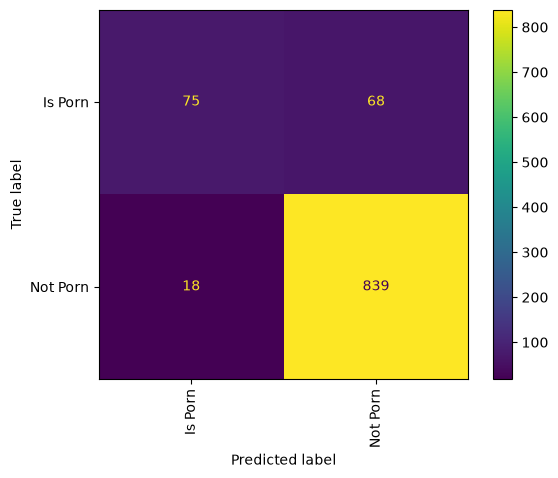

Accuracy Mean": 0.917
"Accuracy SD": 0.015999999999999983
"F1 Macro Mean": 0.798828524833781
"F1 Macro SD": 0.041897726928172965
"F1 Weighted Mean": 0.9088326391885836
"F1 Weighted SD": 0.018429384177128638
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.81      0.52      0.64       143
    Not Porn       0.93      0.98      0.95       857

    accuracy                           0.91      1000
   macro avg       0.87      0.75      0.79      1000
weighted avg       0.91      0.91      0.91      1000

Content Control Porn | Random Forest:


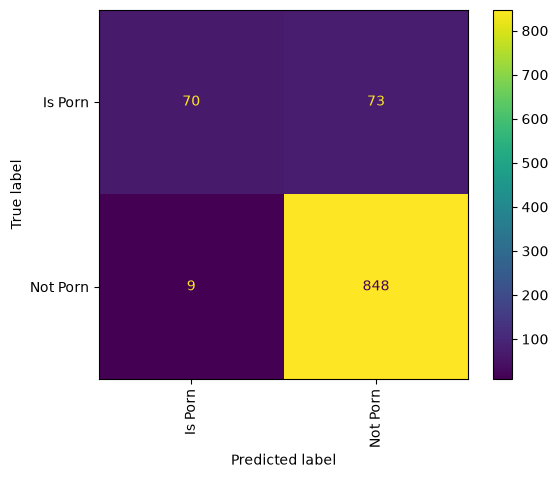

Accuracy Mean": 0.921
"Accuracy SD": 0.008000000000000007
"F1 Macro Mean": 0.7999389334013494
"F1 Macro SD": 0.024942624245204503
"F1 Weighted Mean": 0.9110165177450116
"F1 Weighted SD": 0.01045913831046349
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.89      0.49      0.63       143
    Not Porn       0.92      0.99      0.95       857

    accuracy                           0.92      1000
   macro avg       0.90      0.74      0.79      1000
weighted avg       0.92      0.92      0.91      1000

Content Control Porn | Gradient Boosting:


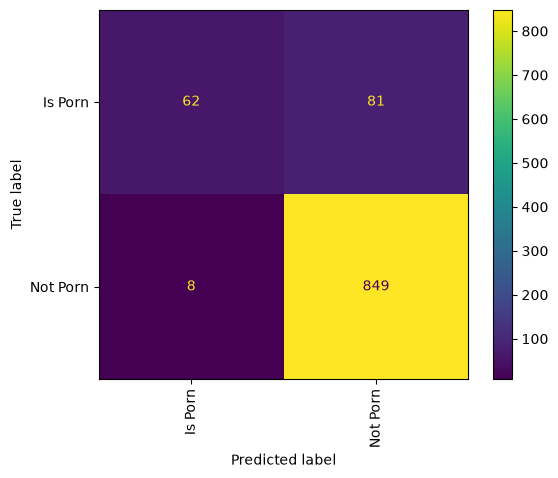

Accuracy Mean": 0.915
"Accuracy SD": 0.010488088481701525
"F1 Macro Mean": 0.7797950797199118
"F1 Macro SD": 0.03741692522760367
"F1 Weighted Mean": 0.9028932251006891
"F1 Weighted SD": 0.015030049986423011
Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.89      0.43      0.58       143
    Not Porn       0.91      0.99      0.95       857

    accuracy                           0.91      1000
   macro avg       0.90      0.71      0.77      1000
weighted avg       0.91      0.91      0.90      1000

Content Control Kink | Multinomial Naive Bayes:


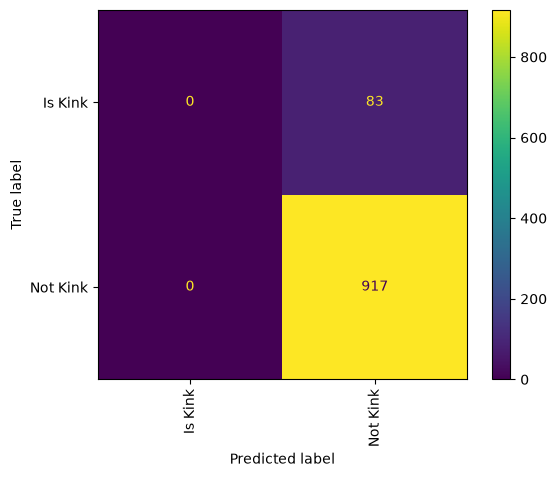

Accuracy Mean": 0.917
"Accuracy SD": 0.0024494897427831805
"F1 Macro Mean": 0.4783507397737162
"F1 Macro SD": 0.0006662015183809864
"F1 Weighted Mean": 0.8772985204525675
"F1 Weighted SD": 0.003566576448804388
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.00      0.00      0.00        83
    Not Kink       0.92      1.00      0.96       917

    accuracy                           0.92      1000
   macro avg       0.46      0.50      0.48      1000
weighted avg       0.84      0.92      0.88      1000

Content Control Kink | Complement Naive Bayes:


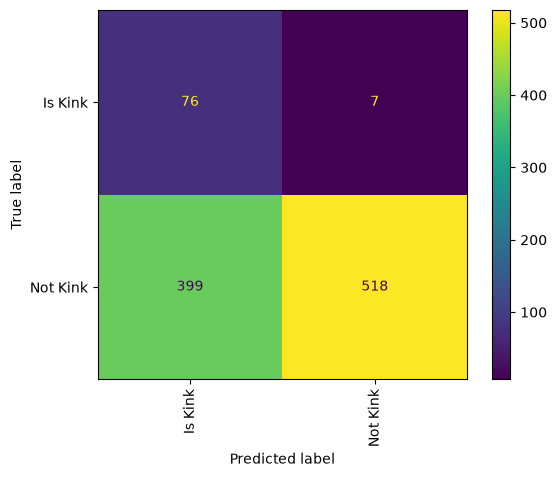

Accuracy Mean": 0.594
"Accuracy SD": 0.027820855486487137
"F1 Macro Mean": 0.49565655225568345
"F1 Macro SD": 0.022765529370925987
"F1 Weighted Mean": 0.6811602199748525
"F1 Weighted SD": 0.022605457601707502
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.16      0.92      0.27        83
    Not Kink       0.99      0.56      0.72       917

    accuracy                           0.59      1000
   macro avg       0.57      0.74      0.50      1000
weighted avg       0.92      0.59      0.68      1000

Content Control Kink | Linear Support Vector Classification:


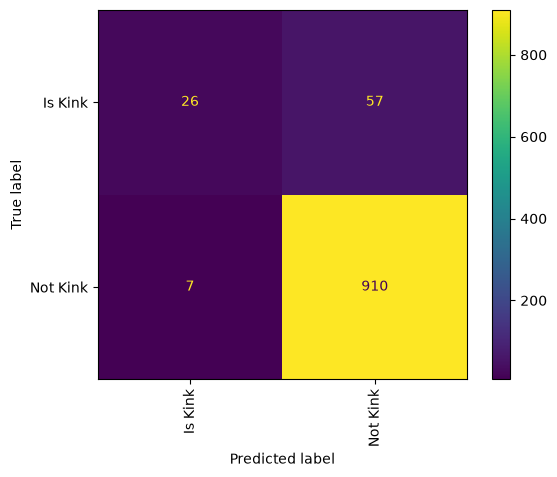

Accuracy Mean": 0.9359999999999999
"Accuracy SD": 0.011575836902790194
"F1 Macro Mean": 0.7041229383580803
"F1 Macro SD": 0.06116318379256005
"F1 Weighted Mean": 0.9225493763308898
"F1 Weighted SD": 0.015436594523308002
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.79      0.31      0.45        83
    Not Kink       0.94      0.99      0.97       917

    accuracy                           0.94      1000
   macro avg       0.86      0.65      0.71      1000
weighted avg       0.93      0.94      0.92      1000

Content Control Kink | Logistic Regression:


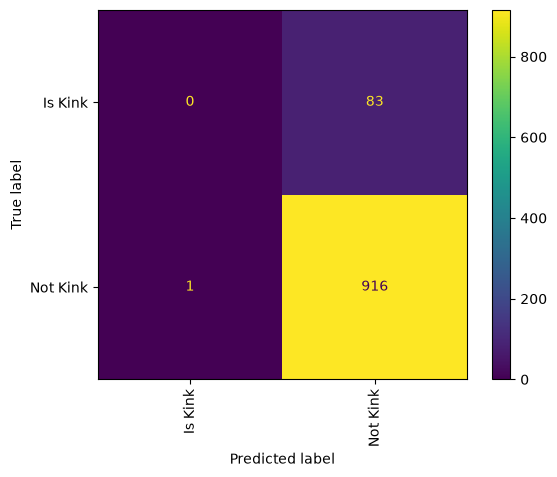

Accuracy Mean": 0.916
"Accuracy SD": 0.0020000000000000018
"F1 Macro Mean": 0.4780787641427328
"F1 Macro SD": 0.000543951261966935
"F1 Weighted Mean": 0.876798085291558
"F1 Weighted SD": 0.003057819657653562
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.00      0.00      0.00        83
    Not Kink       0.92      1.00      0.96       917

    accuracy                           0.92      1000
   macro avg       0.46      0.50      0.48      1000
weighted avg       0.84      0.92      0.88      1000

Content Control Kink | K-Nearest Neighbors:


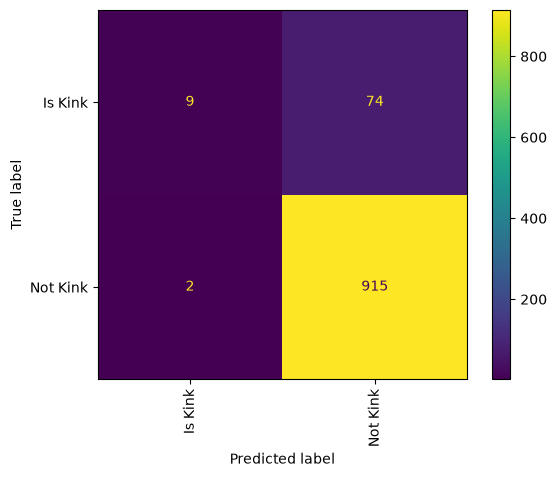

Accuracy Mean": 0.924
"Accuracy SD": 0.006633249580710806
"F1 Macro Mean": 0.5713803934874968
"F1 Macro SD": 0.06465889818067368
"F1 Weighted Mean": 0.8958514612066326
"F1 Weighted SD": 0.011971119477223966
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.82      0.11      0.19        83
    Not Kink       0.93      1.00      0.96       917

    accuracy                           0.92      1000
   macro avg       0.87      0.55      0.58      1000
weighted avg       0.92      0.92      0.90      1000

Content Control Kink | Support Vector Machines:


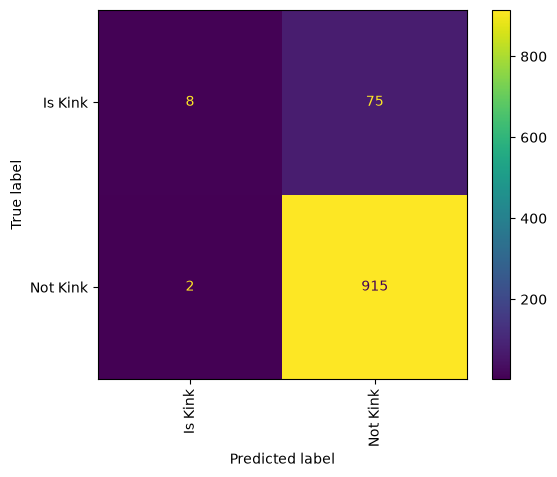

Accuracy Mean": 0.923
"Accuracy SD": 0.006782329983125274
"F1 Macro Mean": 0.5606011189458046
"F1 Macro SD": 0.06565741509424285
"F1 Weighted Mean": 0.8936017927621718
"F1 Weighted SD": 0.012450077107495074
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.80      0.10      0.17        83
    Not Kink       0.92      1.00      0.96       917

    accuracy                           0.92      1000
   macro avg       0.86      0.55      0.57      1000
weighted avg       0.91      0.92      0.89      1000

Content Control Kink | Decision Trees:


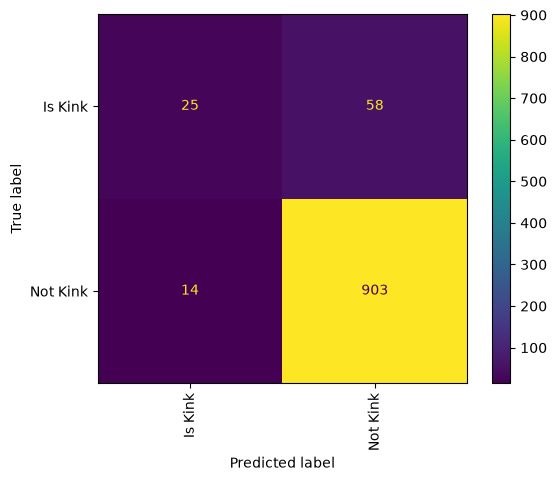

Accuracy Mean": 0.932
"Accuracy SD": 0.012884098726725106
"F1 Macro Mean": 0.7124733483147236
"F1 Macro SD": 0.050326626153638775
"F1 Weighted Mean": 0.9218706345202665
"F1 Weighted SD": 0.014874315529279532
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.64      0.30      0.41        83
    Not Kink       0.94      0.98      0.96       917

    accuracy                           0.93      1000
   macro avg       0.79      0.64      0.69      1000
weighted avg       0.91      0.93      0.92      1000

Content Control Kink | Random Forest:


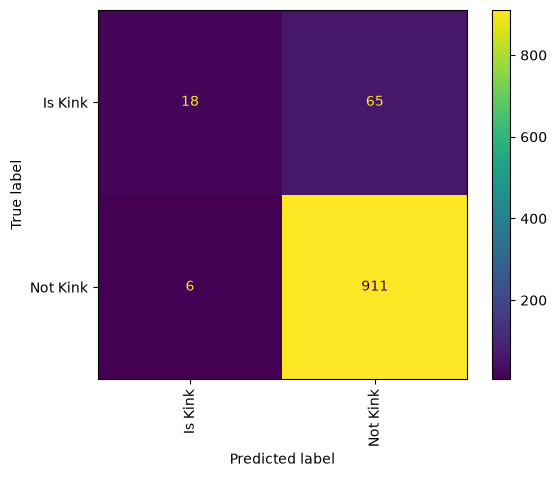

Accuracy Mean": 0.93
"Accuracy SD": 0.01264911064067351
"F1 Macro Mean": 0.6541811453746391
"F1 Macro SD": 0.07261070662564609
"F1 Weighted Mean": 0.9117437479318118
"F1 Weighted SD": 0.017869808063091235
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.75      0.22      0.34        83
    Not Kink       0.93      0.99      0.96       917

    accuracy                           0.93      1000
   macro avg       0.84      0.61      0.65      1000
weighted avg       0.92      0.93      0.91      1000

Content Control Kink | Gradient Boosting:


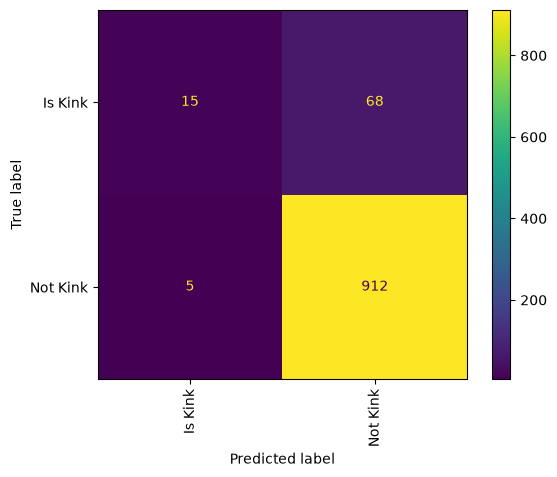

Accuracy Mean": 0.9269999999999999
"Accuracy SD": 0.009273618495495711
"F1 Macro Mean": 0.6237879818281602
"F1 Macro SD": 0.05276325034305386
"F1 Weighted Mean": 0.9055931551407884
"F1 Weighted SD": 0.011872058569090543
Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.75      0.18      0.29        83
    Not Kink       0.93      0.99      0.96       917

    accuracy                           0.93      1000
   macro avg       0.84      0.59      0.63      1000
weighted avg       0.92      0.93      0.91      1000



Classifier,Classification,Accuracy Mean,Accuracy SD,Precision Macro Mean,Precision Macro SD,Precision Weighted Mean,Precision Weighted SD,Recall Macro Mean,Recall Macro SD,Recall Weighted Mean,Recall Weighted SD,F1 Macro Mean,F1 Macro SD,F1 Weighted Mean,F1 Weighted SD
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Multinomial Naive Bayes""","""Character-Related Category""",0.64,0.019235,0.515654,0.045626,0.66222,0.033498,0.339728,0.022659,0.64,0.019235,0.363358,0.028009,0.581849,0.025457
"""Complement Naive Bayes""","""Character-Related Category""",0.553,0.01077,0.584742,0.082689,0.71071,0.01439,0.508616,0.044861,0.553,0.01077,0.489649,0.05641,0.582919,0.013959
"""Linear Support Vector Classifi…","""Character-Related Category""",0.703,0.005099,0.63319,0.066689,0.70745,0.008933,0.485342,0.012152,0.703,0.005099,0.522147,0.02295,0.683866,0.006853
"""Logistic Regression""","""Character-Related Category""",0.641,0.016553,0.573332,0.089994,0.682153,0.038406,0.357583,0.016988,0.641,0.016553,0.390566,0.023319,0.59238,0.02032
"""K-Nearest Neighbors""","""Character-Related Category""",0.589,0.08315,0.59385,0.123037,0.672033,0.041817,0.410929,0.032523,0.589,0.08315,0.42078,0.052876,0.583694,0.057614
"""Support Vector Machines""","""Character-Related Category""",0.649,0.017436,0.573376,0.099146,0.68305,0.043551,0.370084,0.014674,0.649,0.017436,0.403461,0.020438,0.605041,0.018561
"""Decision Trees""","""Character-Related Category""",0.66,0.017029,0.60544,0.040023,0.670899,0.019563,0.436153,0.012489,0.66,0.017029,0.471972,0.018878,0.634592,0.019946
"""Random Forest""","""Character-Related Category""",0.649,0.020591,0.59397,0.061215,0.678198,0.033661,0.393183,0.024925,0.649,0.020591,0.429445,0.030579,0.614321,0.025107
"""Gradient Boosting""","""Character-Related Category""",0.635,0.02569,0.670036,0.094638,0.698663,0.036175,0.411395,0.059183,0.635,0.02569,0.455944,0.063136,0.600378,0.02609


In [102]:
classifiers = [MultinomialNB(), ComplementNB(), LinearSVC(), LogisticRegression(), KNeighborsClassifier(), SVC(), DecisionTreeClassifier(), RandomForestClassifier(), GradientBoostingClassifier()]
classifier_names = ['Multinomial Naive Bayes', 'Complement Naive Bayes', 'Linear Support Vector Classification', 'Logistic Regression', 'K-Nearest Neighbors', 'Support Vector Machines', 'Decision Trees', 'Random Forest', 'Gradient Boosting']
classification = ['Character-Related Category', 'Narrative-Related Category', 'Content Control Porn', 'Content Control Kink']

df_stats = pl.DataFrame()
i = 0
for y_value in y_values:
    for j in range(len(classifiers)):
        df_stats = pl.concat([df_stats, compare_classifiers(y_value, classifiers[j], classifier_names[j], classification[i])])
    i += 1

df_stats.show(36)

## 3. Annotating the Content-Control Category

In [118]:
# Read the files
df_top_1000 = pl.read_csv("./data/top_1000_tags.csv")
df_content_control = pl.read_csv("./data/df_unique.csv")

# Turn the series into a list
content_control_list = df_content_control.to_series().to_list()
type(content_control_list)

list

In [119]:
X_porn = df_top_1000["Tag"]
y_porn = df_top_1000["Porn"]

X_kink = df_top_1000["Tag"]
y_kink = df_top_1000["Kink"]

# Create a Pipeline
pipeLinearSVC = Pipeline([
    ('tfidf', TfidfVectorizer()),('clf', LinearSVC())
])

LinearSVCPorn = pipeLinearSVC.fit(X_porn, y_porn)
LinearSVCKink = pipeLinearSVC.fit(X_kink, y_kink)

In [120]:
def content_control(tag):
    """
    Labels the additional tags.

    Parameter:
        tag (string): The additional tag that should be assigned an annotation label.
    Returns:
        df_temp_content_control (DataFrame): Contains the tag and the Porn and Kink annotation labels
    """
    tag_porn = LinearSVCPorn.predict([tag])
    tag_kink = LinearSVCKink.predict([tag])

    df_temp_content_control = pl.DataFrame({
        "Tag": tag,
        "Porn": tag_porn,
        "Kink": tag_kink
    })

    return df_temp_content_control

In [121]:
df_content_control_labels = pl.DataFrame()
# Iterate over the additional tags in the content_control_list
for tag in content_control_list:
    df_content_control_labels = pl.concat([df_content_control_labels, content_control(tag)]) # Concat the results to the df_content_control_labels DataFrame

df_content_control_labels

Tag,Porn,Kink
str,str,str
"""Fluff""","""Not Kink""","""Not Kink"""
"""Angst""","""Not Kink""","""Not Kink"""
"""AvaLance""","""Not Kink""","""Not Kink"""
"""Hurt/Comfort""","""Not Kink""","""Not Kink"""
"""Angst with a Happy Ending""","""Not Kink""","""Not Kink"""
…,…,…
"""Miles Morales is smitten""","""Not Kink""","""Not Kink"""
"""y/n cries""","""Not Kink""","""Not Kink"""
"""texting while fighting""","""Not Kink""","""Not Kink"""


In [122]:
df_content_control_labels.write_csv('data/df_content_control.csv') # Save the result as a CSV file